# Container Resource Optimization with M/M/1 Queueing Theory

In cloud and containerized environments (e.g., Kubernetes pods/containers), choosing the right **CPU** (in millicores) and **RAM** (in MB) limits is a classic optimization trade-off:
- **Allocating too few resources** pushes container utilization ($\rho = \lambda / \mu$) close to $100\%$, causing **nonlinear queueing delays** and violating Service Level Agreements (SLAs).
- **Allocating too many resources** keeps latency low, but wastes infrastructure capacity and budget.

In this notebook, we combine **M/M/1 Queueing Theory** with **Pyomo Mathematical Optimization** to find the minimum CPU ($\in [500, 2000]\text{ mCPU}$) and RAM allocation that guarantees a target mean response time SLA ($W \le W_{\max}$).

## 1. Mathematical Model Overview

We model the container as a single-server **M/M/1 queue**:
- **Arrival Rate ($\lambda$)**: Requests arrive according to a Poisson process (mean $\lambda\text{ req/s}$).
- **Service Rate ($\mu$)**: Processing speed is proportional to allocated CPU:
  $$\mu(\text{CPU}) = \alpha_{\text{cpu}} \cdot \text{CPU}$$
- **Memory Requirement ($\text{RAM}$)**: The container needs a base memory footprint plus memory proportional to its processing throughput:
  $$\text{RAM} \ge \text{RAM}_{\text{base}} + \beta_{\text{ram}} \cdot \mu$$
- **Mean Response Time ($W$)**: In steady state ($\mu > \lambda$), total time in the system (waiting in queue + service) is:
  $$W = \frac{1}{\mu - \lambda} \le W_{\max} \iff \mu - \lambda \ge \frac{1}{W_{\max}}$$

In [1]:
import os
ASSETS_DIR = os.path.join("assets", "part1") if os.path.exists("assets") else os.path.join("..", "assets", "part1")
os.makedirs(ASSETS_DIR, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyomo.environ as pyo

from container_queue_model import (
    build_container_queue_model,
    solve_model,
    print_solution,
)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

## 2. Solving the Baseline Scenario

Let's solve the baseline problem with:
- Arrival rate $\lambda = 50\text{ req/s}$
- Maximum average response time SLA $W_{\max} = 50\text{ ms}$ ($0.05\text{ s}$)
- CPU throughput coefficient $\alpha_{\text{cpu}} = 0.08\text{ req/(s}\cdot\text{mCPU)}$ (i.e., $1000\text{ mCPU}$ can process $80\text{ req/s}$)
- Base RAM $\text{RAM}_{\text{base}} = 128\text{ MB}$ and $\beta_{\text{ram}} = 4.0\text{ MB/(req/s)}$
- CPU bounds: $[500, 2000]\text{ millicores}$

In [2]:
model = build_container_queue_model(
    lambda_req=50.0,
    w_max=0.05,
    alpha_cpu=0.08,
    ram_base=128.0,
    beta_ram=4.0,
    cpu_bounds=(500.0, 2000.0),
)

solve_model(model)
print_solution(model)

  CASE 1: SINGLE-CONTAINER M/M/1 RESOURCE OPTIMIZATION PROBLEM
Workload, SLA & System Parameters:
  Arrival Rate (lambda)         : 50.00 req/s
  Max Response Time SLA (W_max) : 50.00 ms (0.0500 s)
  CPU Throughput (alpha_cpu)    : 0.0800 req/s per millicore
  Base RAM Overhead (ram_base)  : 128.00 MB
  Working RAM Factor (beta_ram) : 4.00 MB per (req/s)
  CPU Allocation Bounds         : [500, 2000] millicores
  RAM Allocation Bounds         : [128, 4096] MB
  Objective Weights (CPU, RAM)  : w_cpu=1.00, w_ram=1.00
************************************************************************
  OPTIMAL SOLUTION FOUND
************************************************************************
Optimal Resource Allocation:
  CPU Allocated                 : 875.00 millicores (bounds: [500, 2000])
  RAM Allocated                 : 408.00 MB (bounds: [128, 4096])
  Service Capacity (mu)         : 70.00 req/s
------------------------------------------------------------------------
Queueing Metrics (M/M

### Why doesn't the optimizer allocate just enough CPU to match $\lambda = 50\text{ req/s}$?

If the container only processed $\mu = 50\text{ req/s}$ (which requires $50 / 0.08 = 625\text{ mCPU}$), utilization would be $\rho = \lambda / \mu = 100\%$, and the queue length and response time $W = \frac{1}{\mu - \lambda}$ would grow to **infinity**!

To satisfy $W \le 0.05\text{ s}$, the container needs an extra capacity buffer of $\frac{1}{W_{\max}} = \frac{1}{0.05} = 20\text{ req/s}$ above the arrival rate:
- **Required Service Rate**: $\mu^* = 50 + 20 = 70\text{ req/s}$
- **Optimal CPU**: $\text{CPU}^* = 70 / 0.08 = 875\text{ mCPU}$ (resulting in $\rho^* = 71.43\%$ utilization)
- **Optimal RAM**: $\text{RAM}^* = 128 + 4 \times 70 = 408\text{ MB}$

In [3]:
# TODO Crie um grafico detalhando o espaco de busca do problema

## 3. Visualizing the M/M/1 Response Time & Queueing Explosion

Let's plot how the average response time $W$ and waiting time in queue $W_q$ behave as we vary CPU from the stability threshold ($625\text{ mCPU}$) up to the container maximum ($2000\text{ mCPU}$).

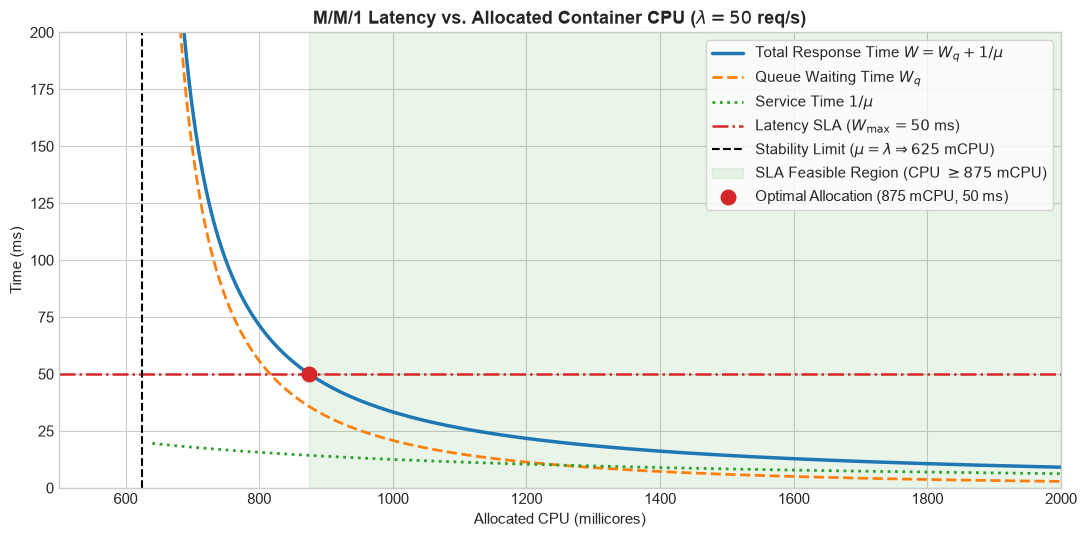

In [4]:
lambda_req = 50.0
alpha_cpu = 0.08
w_max_ms = 50.0

cpu_stability = lambda_req / alpha_cpu  # 625 mCPU (where mu == lambda)
cpu_vals = np.linspace(cpu_stability + 15, 2000, 400)
mu_vals = alpha_cpu * cpu_vals

w_total_ms = (1.0 / (mu_vals - lambda_req)) * 1000.0
w_queue_ms = (lambda_req / (mu_vals * (mu_vals - lambda_req))) * 1000.0
service_time_ms = (1.0 / mu_vals) * 1000.0

opt_cpu = pyo.value(model.cpu)
opt_w_ms = pyo.value(model.response_time) * 1000.0

fig, ax = plt.subplots(figsize=(11, 5.5))

ax.plot(cpu_vals, w_total_ms, label=r"Total Response Time $W = W_q + 1/\mu$", color="#1f77b4", lw=2.5)
ax.plot(cpu_vals, w_queue_ms, label=r"Queue Waiting Time $W_q$", color="#ff7f0e", ls="--", lw=2)
ax.plot(cpu_vals, service_time_ms, label=r"Service Time $1/\mu$", color="#2ca02c", ls=":", lw=2)

# SLA & Stability lines
ax.axhline(w_max_ms, color="#d62728", ls="-.", lw=1.8, label=rf"Latency SLA ($W_{{\max}} = {w_max_ms:.0f}$ ms)")
ax.axvline(cpu_stability, color="black", ls="--", lw=1.5, label=rf"Stability Limit ($\mu = \lambda \Rightarrow {cpu_stability:.0f}$ mCPU)")

# Highlight feasible region and optimal point
ax.axvspan(opt_cpu, 2000, color="#2ca02c", alpha=0.10, label=r"SLA Feasible Region (CPU $\geq 875$ mCPU)")
ax.scatter([opt_cpu], [opt_w_ms], color="#d62728", s=110, zorder=5,
           label=f"Optimal Allocation ({opt_cpu:.0f} mCPU, {opt_w_ms:.0f} ms)")

ax.set_xlim(500, 2000)
ax.set_ylim(0, 200)
ax.set_title(r"M/M/1 Latency vs. Allocated Container CPU ($\lambda = 50$ req/s)", fontsize=13, fontweight="bold")
ax.set_xlabel("Allocated CPU (millicores)")
ax.set_ylabel("Time (ms)")
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "01_response_time_vs_cpu.png"), dpi=150, bbox_inches="tight")
plt.show()

### Key Insights from the Latency Curve
1. **Queueing Dominates Near Saturation**: Notice how the pure service time $1/\mu$ (green dotted line) changes very gradually between $650$ and $2000\text{ mCPU}$, whereas the **queue waiting time $W_q$** (orange dashed line) shoots up hyperbolically as CPU approaches $625\text{ mCPU}$.
2. **Active SLA Binding**: Because the objective minimizes CPU and RAM, the optimal solution sits right on the boundary of the feasible region ($\text{CPU}^* = 875\text{ mCPU}$, $W = 50\text{ ms}$).

## 4. Workload Sensitivity Analysis: Varying Arrival Rate ($\lambda$)

How do optimal CPU, RAM, and container utilization ($\rho$) evolve as incoming traffic $\lambda$ increases from $10\text{ req/s}$ to $135\text{ req/s}$? Let's solve the Pyomo model across a grid of arrival rates.

In [5]:
lambda_grid = np.linspace(10, 135, 26)
records = []

for lam in lambda_grid:
    m = build_container_queue_model(
        lambda_req=float(lam),
        w_max=0.05,
        alpha_cpu=0.08,
        ram_base=128.0,
        beta_ram=4.0,
        cpu_bounds=(500.0, 2000.0),
    )
    solve_model(m)
    records.append({
        "lambda_req": lam,
        "cpu_mcpu": pyo.value(m.cpu),
        "ram_mb": pyo.value(m.ram),
        "mu_req_s": pyo.value(m.mu),
        "utilization_pct": pyo.value(m.utilization) * 100.0,
        "response_time_ms": pyo.value(m.response_time) * 1000.0,
        "avg_queue_len": pyo.value(m.avg_requests_in_system),
    })

df_Traffic = pd.DataFrame(records)
df_Traffic.head(8)

,lambda_req,cpu_mcpu,ram_mb,mu_req_s,utilization_pct,response_time_ms,avg_queue_len
0,10.0,500.0,288.0,40.0,25.000000,33.333333,0.333333
1,15.0,500.0,288.0,40.0,37.500000,40.000000,0.600000
2,20.0,500.0,288.0,40.0,50.000000,50.000000,1.000000
3,25.0,562.5,308.0,45.0,55.555556,50.000000,1.250000
4,30.0,625.0,328.0,50.0,60.000000,50.000000,1.500000
5,35.0,687.5,348.0,55.0,63.636364,50.000000,1.750000
6,40.0,750.0,368.0,60.0,66.666667,50.000000,2.000000
7,45.0,812.5,388.0,65.0,69.230769,50.000000,2.250000


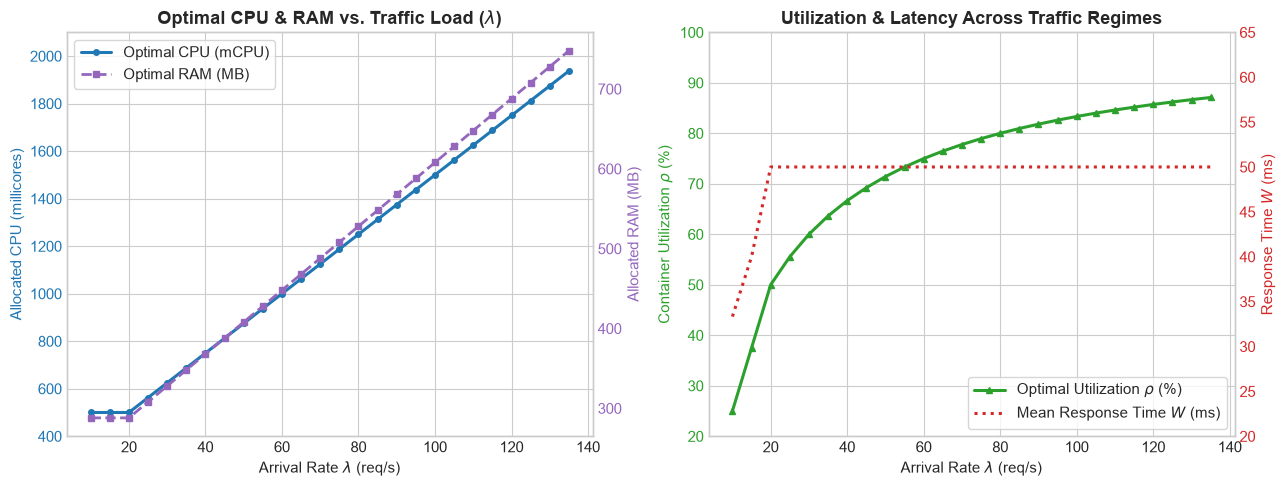

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left Plot: CPU and RAM vs Arrival Rate
ax1 = axes[0]
color_cpu = "#1f77b4"
color_ram = "#9467bd"

l1 = ax1.plot(df_Traffic["lambda_req"], df_Traffic["cpu_mcpu"], marker="o", markersize=4,
              color=color_cpu, lw=2.2, label="Optimal CPU (mCPU)")
ax1.set_xlabel(r"Arrival Rate $\lambda$ (req/s)")
ax1.set_ylabel("Allocated CPU (millicores)", color=color_cpu)
ax1.tick_params(axis="y", labelcolor=color_cpu)
ax1.set_ylim(400, 2100)

ax1_ram = ax1.twinx()
l2 = ax1_ram.plot(df_Traffic["lambda_req"], df_Traffic["ram_mb"], marker="s", markersize=4,
                  color=color_ram, ls="--", lw=2.0, label="Optimal RAM (MB)")
ax1_ram.set_ylabel("Allocated RAM (MB)", color=color_ram)
ax1_ram.tick_params(axis="y", labelcolor=color_ram)
ax1_ram.grid(False)

lines = l1 + l2
labels = [line.get_label() for line in lines]
ax1.legend(lines, labels, loc="upper left", frameon=True)
ax1.set_title(r"Optimal CPU & RAM vs. Traffic Load ($\lambda$)", fontweight="bold")

# Right Plot: Utilization & Response Time vs Arrival Rate
ax2 = axes[1]
l3 = ax2.plot(df_Traffic["lambda_req"], df_Traffic["utilization_pct"], marker="^", markersize=4,
              color="#2ca02c", lw=2.2, label=r"Optimal Utilization $\rho$ (%)")
ax2.set_xlabel(r"Arrival Rate $\lambda$ (req/s)")
ax2.set_ylabel(r"Container Utilization $\rho$ (%)", color="#2ca02c")
ax2.tick_params(axis="y", labelcolor="#2ca02c")
ax2.set_ylim(20, 100)

ax2_w = ax2.twinx()
l4 = ax2_w.plot(df_Traffic["lambda_req"], df_Traffic["response_time_ms"], color="#d62728",
                ls=":", lw=2.2, label="Mean Response Time $W$ (ms)")
ax2_w.set_ylabel("Response Time $W$ (ms)", color="#d62728")
ax2_w.tick_params(axis="y", labelcolor="#d62728")
ax2_w.set_ylim(20, 65)
ax2_w.grid(False)

lines2 = l3 + l4
labels2 = [line.get_label() for line in lines2]
ax2.legend(lines2, labels2, loc="lower right", frameon=True)
ax2.set_title("Utilization & Latency Across Traffic Regimes", fontweight="bold")

plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "02_workload_scaling.png"), dpi=150, bbox_inches="tight")
plt.show()

### Explaining the Two Operating Regimes
1. **Low-Traffic Regime ($\lambda \le 20\text{ req/s}$)**:
   - The minimum CPU bound ($500\text{ mCPU} \Rightarrow \mu = 40\text{ req/s}$) is active.
   - Because the container cannot be scaled below $500\text{ mCPU}$, it has excess capacity and achieves response times *strictly below* $50\text{ ms}$ (e.g., $W = 33.3\text{ ms}$ at $\lambda = 10\text{ req/s}$).
2. **SLA-Driven Scaling Regime ($20 < \lambda \le 140\text{ req/s}$)**:
   - CPU and RAM grow linearly with $\lambda$ to maintain the exact spare capacity buffer $\mu - \lambda = 20\text{ req/s}$.
   - Interestingly, **higher-traffic containers can safely run at higher CPU utilization ($\rho$)** while meeting the exact same $50\text{ ms}$ SLA! At $\lambda = 30\text{ req/s}$, $\rho^* = 60\%$; at $\lambda = 135\text{ req/s}$, $\rho^* = 87.1\%$. This is a classic queueing scale economy: what determines $W = \frac{1}{\mu - \lambda}$ is the *absolute spare capacity* $(\mu - \lambda)$, not the ratio $\lambda/\mu$.
3. **Saturation Limit ($\lambda > 140\text{ req/s}$)**:
   - At $\lambda = 140\text{ req/s}$, the container hits its upper bound of $2000\text{ mCPU}$ ($\mu = 160\text{ req/s}$). Beyond this arrival rate, horizontal scaling (adding more container replicas in an M/M/c model) becomes mandatory.

## 5. Cost vs. Latency SLA Trade-Off (Pareto Front)

How much extra CPU and RAM do we pay for stricter latency targets? Let's fix $\lambda = 50\text{ req/s}$ and sweep the SLA target $W_{\max}$ from $12\text{ ms}$ to $150\text{ ms}$.

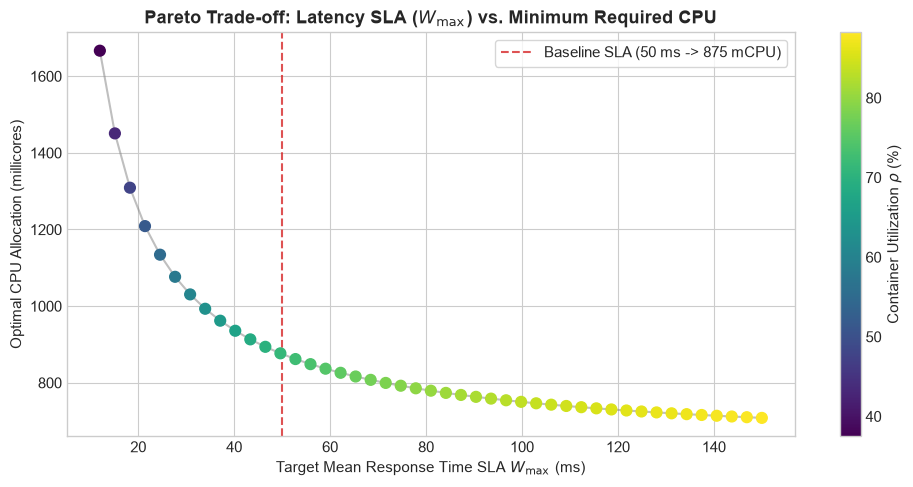

In [7]:
w_max_ms_grid = np.linspace(12, 150, 45)
sla_records = []

for w_ms in w_max_ms_grid:
    m = build_container_queue_model(
        lambda_req=50.0,
        w_max=float(w_ms / 1000.0),
        alpha_cpu=0.08,
        ram_base=128.0,
        beta_ram=4.0,
        cpu_bounds=(500.0, 2000.0),
    )
    solve_model(m)
    sla_records.append({
        "w_max_ms": w_ms,
        "cpu_mcpu": pyo.value(m.cpu),
        "ram_mb": pyo.value(m.ram),
        "obj_cost": pyo.value(m.total_resource_cost),
        "utilization_pct": pyo.value(m.utilization) * 100.0,
    })

df_sla = pd.DataFrame(sla_records)

fig, ax = plt.subplots(figsize=(10, 5))
sc = ax.scatter(
    df_sla["w_max_ms"],
    df_sla["cpu_mcpu"],
    c=df_sla["utilization_pct"],
    cmap="viridis",
    s=60,
    zorder=4,
)
ax.plot(df_sla["w_max_ms"], df_sla["cpu_mcpu"], color="gray", alpha=0.5, lw=1.5)

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label(r"Container Utilization $\rho$ (%)")

ax.axvline(50, color="#d62728", ls="--", alpha=0.8, label="Baseline SLA (50 ms -> 875 mCPU)")
ax.set_title(r"Pareto Trade-off: Latency SLA ($W_{\max}$) vs. Minimum Required CPU", fontweight="bold")
ax.set_xlabel(r"Target Mean Response Time SLA $W_{\max}$ (ms)")
ax.set_ylabel("Optimal CPU Allocation (millicores)")
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "03_sla_sensitivity.png"), dpi=150, bbox_inches="tight")
plt.show()

## 6. Visualizing the 2D Decision Space (CPU vs. RAM)

Finally, let's inspect the 2D optimization space $(\text{CPU}, \text{RAM})$ for our baseline scenario ($\lambda = 50\text{ req/s}, W_{\max} = 50\text{ ms}$), showing the objective function contours, the SLA constraint boundary, the RAM provisioning boundary, and the optimal corner solution.

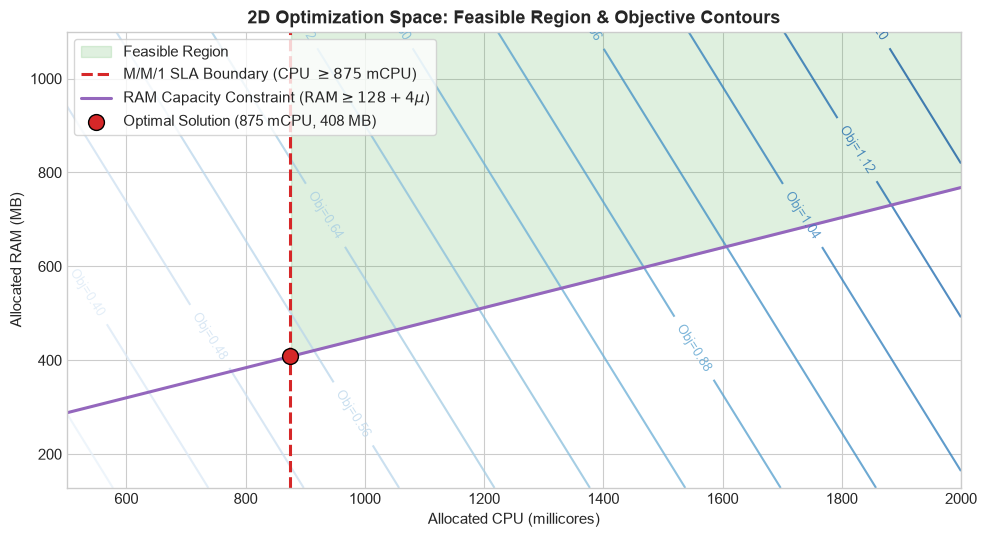

In [8]:
cpu_grid = np.linspace(500, 2000, 300)
ram_grid = np.linspace(128, 1200, 300)
CPU_M, RAM_M = np.meshgrid(cpu_grid, ram_grid)

# Normalized objective function contours
OBJ = (CPU_M / 2000.0) + (RAM_M / 4096.0)

# Constraint boundaries
cpu_min_sla = (50.0 + 1.0 / 0.05) / 0.08  # 875 mCPU
ram_min_curve = 128.0 + 4.0 * (0.08 * cpu_grid)

fig, ax = plt.subplots(figsize=(10, 5.5))

contours = ax.contour(CPU_M, RAM_M, OBJ, levels=12, cmap="Blues", alpha=0.75)
ax.clabel(contours, inline=True, fontsize=9, fmt="Obj=%.2f")

# Shade feasible region: CPU >= cpu_min_sla and RAM >= ram_min_curve
ax.fill_between(
    cpu_grid,
    np.maximum(ram_min_curve, 128),
    1200,
    where=(cpu_grid >= cpu_min_sla),
    color="#2ca02c",
    alpha=0.15,
    label="Feasible Region",
)

ax.axvline(cpu_min_sla, color="#d62728", lw=2.2, ls="--", label=rf"M/M/1 SLA Boundary (CPU $\geq {cpu_min_sla:.0f}$ mCPU)")
ax.plot(cpu_grid, ram_min_curve, color="#9467bd", lw=2.2, label=r"RAM Capacity Constraint ($\mathrm{RAM} \geq 128 + 4\mu$)")

ax.scatter([875.0], [408.0], color="#d62728", s=130, zorder=6, edgecolors="black",
           label="Optimal Solution (875 mCPU, 408 MB)")

ax.set_xlim(500, 2000)
ax.set_ylim(128, 1100)
ax.set_title("2D Optimization Space: Feasible Region & Objective Contours", fontweight="bold")
ax.set_xlabel("Allocated CPU (millicores)")
ax.set_ylabel("Allocated RAM (MB)")
ax.legend(loc="upper left", frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "04_feasible_region_contours.png"), dpi=150, bbox_inches="tight")
plt.show()

## 7. Detailed Problem Search Space Decomposition

To fully understand the optimization landscape of **Case 1**, we decompose the entire bounded box $\Omega = [500, 2000]\text{ mCPU} \times [128, 4096]\text{ MB}$ into its distinct **feasible** and **infeasible** regimes, and visualize both the **2D constraint taxonomy** (left) and the **3D objective & response-time surface** (right):

1. **Queue Instability Zone ($\mu \le \lambda \iff \text{CPU} \le 625\text{ mCPU}$)**: Utilization $\rho \ge 1$; the queue grows unboundedly ($W \to \infty$).
2. **SLA Violation Zone ($625 < \text{CPU} < 875\text{ mCPU}$)**: The queue is stable ($\rho < 1$), but mean response time exceeds $W_{\max} = 50\text{ ms}$.
3. **RAM Deficit Zone ($\text{CPU} \ge 875\text{ mCPU},\; \text{RAM} < 128 + 0.32\,\text{CPU}$)**: Sufficient CPU to meet latency SLA, but insufficient memory to sustain throughput $\mu$.
4. **Feasible Search Space ($\mathcal{F}$)**: Satisfies all stability, latency SLA, and memory constraints; the linear objective gradient $\nabla f$ pushes the optimum to the lower-left vertex $(875\text{ mCPU}, 408\text{ MB})$.

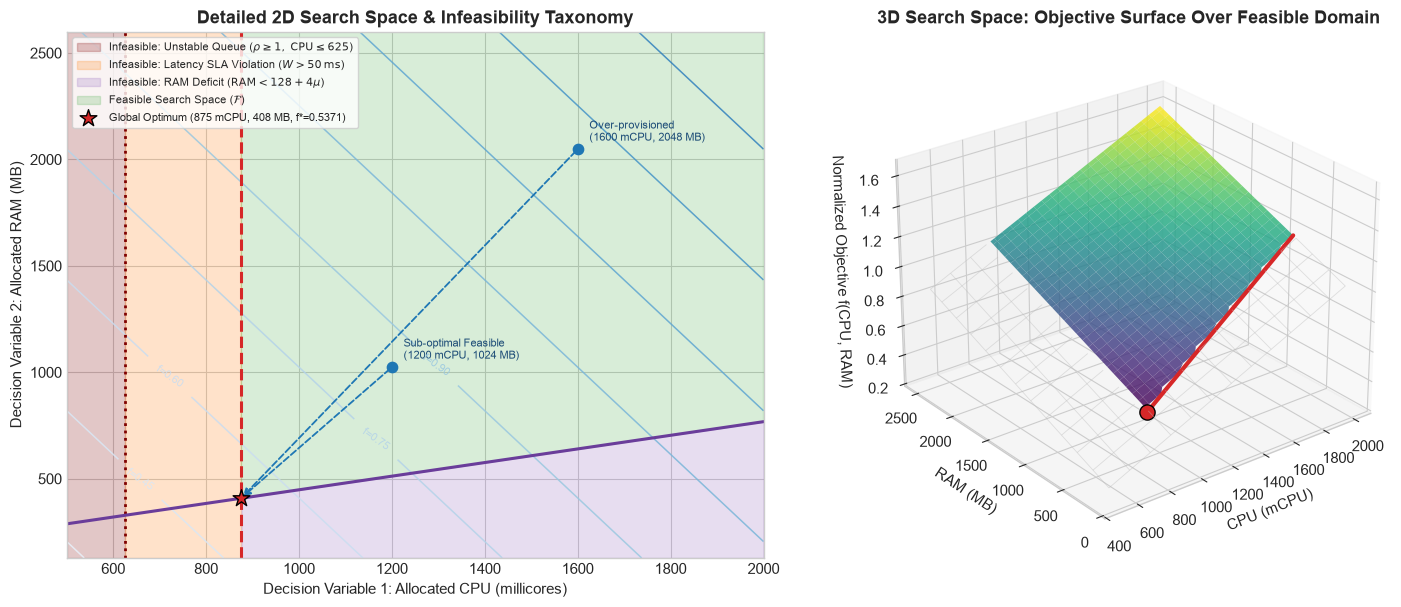

In [9]:
# TODO Crie um grafico detalhando o espaco de busca do problema
cpu_full = np.linspace(500, 2000, 400)
ram_full = np.linspace(128, 4096, 400)
CPU_G, RAM_G = np.meshgrid(cpu_full, ram_full)

OBJ_G = (CPU_G / 2000.0) + (RAM_G / 4096.0)
cpu_unstable = 50.0 / 0.08               # 625 mCPU (mu = lambda)
cpu_sla = (50.0 + 1.0 / 0.05) / 0.08     # 875 mCPU (W = W_max)
ram_req_line = 128.0 + 4.0 * (0.08 * cpu_full)

fig = plt.figure(figsize=(15, 6.2))

# --- Panel 1: Complete 2D Search Space Taxonomy ---
ax1 = fig.add_subplot(1, 2, 1)

# 1) Unstable Queue Region (CPU <= 625)
ax1.axvspan(500, cpu_unstable, color="#7f0000", alpha=0.22, label=r"Infeasible: Unstable Queue ($\rho \geq 1,\; \mathrm{CPU} \leq 625$)")

# 2) SLA Violation Region (625 < CPU < 875)
ax1.axvspan(cpu_unstable, cpu_sla, color="#ff7f0e", alpha=0.22, label=r"Infeasible: Latency SLA Violation ($W > 50\,\mathrm{ms}$)")

# 3) Insufficient RAM Region (CPU >= 875, RAM < ram_req_line)
ax1.fill_between(
    cpu_full, 128, ram_req_line,
    where=(cpu_full >= cpu_sla),
    color="#9467bd", alpha=0.22,
    label=r"Infeasible: RAM Deficit ($\mathrm{RAM} < 128 + 4\mu$)"
)

# 4) Feasible Region (CPU >= 875, RAM >= ram_req_line)
ax1.fill_between(
    cpu_full, ram_req_line, 4096,
    where=(cpu_full >= cpu_sla),
    color="#2ca02c", alpha=0.18,
    label=r"Feasible Search Space ($\mathcal{F}$)"
)

# Objective contours across the entire search box
cs = ax1.contour(CPU_G, RAM_G, OBJ_G, levels=14, cmap="Blues", linewidths=1.1, alpha=0.85)
ax1.clabel(cs, inline=True, fontsize=8, fmt="f=%.2f")

# Boundary lines
ax1.axvline(cpu_unstable, color="#7f0000", lw=2, ls=":")
ax1.axvline(cpu_sla, color="#d62728", lw=2.2, ls="--")
ax1.plot(cpu_full, ram_req_line, color="#6a3d9a", lw=2.2)

# Sample candidate points in the search space
candidates = [
    (1200, 1024, "Sub-optimal Feasible\n(1200 mCPU, 1024 MB)"),
    (1600, 2048, "Over-provisioned\n(1600 mCPU, 2048 MB)"),
]
for cx, cy, clabel in candidates:
    ax1.scatter([cx], [cy], color="#1f77b4", s=55, zorder=5)
    ax1.annotate(
        "", xy=(875, 408), xytext=(cx, cy),
        arrowprops=dict(arrowstyle="->", color="#1f77b4", lw=1.3, ls="--")
    )
    ax1.text(cx + 25, cy + 40, clabel, fontsize=8, color="#1f4e78")

# Optimal point
ax1.scatter([875], [408], color="#d62728", s=160, marker="*", zorder=7, edgecolors="black",
            label="Global Optimum (875 mCPU, 408 MB, f*=0.5371)")

ax1.set_xlim(500, 2000)
ax1.set_ylim(128, 2600)
ax1.set_title("Detailed 2D Search Space & Infeasibility Taxonomy", fontweight="bold")
ax1.set_xlabel("Decision Variable 1: Allocated CPU (millicores)")
ax1.set_ylabel("Decision Variable 2: Allocated RAM (MB)")
ax1.legend(loc="upper left", fontsize=8.2, frameon=True)

# --- Panel 2: 3D Search Space Surface (CPU x RAM x Objective Value) ---
ax2 = fig.add_subplot(1, 2, 2, projection="3d")

cpu_3d = np.linspace(500, 2000, 60)
ram_3d = np.linspace(128, 2500, 60)
C3, R3 = np.meshgrid(cpu_3d, ram_3d)
O3 = (C3 / 2000.0) + (R3 / 4096.0)

# Mask infeasible vs feasible on the 3D objective plane
feasible_mask = (C3 >= cpu_sla) & (R3 >= (128.0 + 0.32 * C3))
O3_feas = np.where(feasible_mask, O3, np.nan)
O3_infeas = np.where(~feasible_mask, O3, np.nan)

ax2.plot_wireframe(C3, R3, O3_infeas, rstride=5, cstride=5, color="#bdbdbd", alpha=0.45, linewidth=0.6)
surf = ax2.plot_surface(C3, R3, O3_feas, cmap="viridis", alpha=0.82, edgecolor="none")

# Plot the active boundary trajectory along RAM = 128 + 0.32*CPU for CPU >= 875
cpu_bound = np.linspace(cpu_sla, 2000, 100)
ram_bound = 128.0 + 0.32 * cpu_bound
obj_bound = (cpu_bound / 2000.0) + (ram_bound / 4096.0)
ax2.plot(cpu_bound, ram_bound, obj_bound, color="#d62728", lw=3.0, label="Active Boundary Ridge")

# Plot optimal vertex in 3D
ax2.scatter([875], [408], [875/2000 + 408/4096], color="#d62728", s=120, edgecolors="black", depthshade=False)

ax2.set_title("3D Search Space: Objective Surface Over Feasible Domain", fontweight="bold")
ax2.set_xlabel("CPU (mCPU)")
ax2.set_ylabel("RAM (MB)")
ax2.set_zlabel("Normalized Objective f(CPU, RAM)")
ax2.view_init(elev=26, azim=-128)

plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "05_3d_search_space_taxonomy.png"), dpi=150, bbox_inches="tight")
plt.show()